In [1]:
import os

try:
  os.chdir('../Rで学ぶベイズ統計学入門')
except:
  pass

path = os.getcwd()

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib


from scipy.stats import beta, binom, betabinom, norm


### 2.2 睡眠時間の十分な学生の割合の調査

アメリカの大学生の睡眠時間について調査したい。
平均的な成人であれば８時間の睡眠が医者によって推奨されている。
では、大学生の何割が最低８時間の睡眠をとっているであろうか。

少なくとも８時間睡眠をとった学生の割合を $ p $ で表す。
事前予測として、大学生の睡眠時間が８時間以上の割合 $ p $ は 0.3と見積もる。

大学生27人を抽出した調査が行われ、このうち１１人が前夜に８時間以上の睡眠をとったことになっている。

事前の予測と実験結果から $ p $ の値を推定する。


1. 問題の整理
* ８時間以上眠った学生＝成功
    * 成功率 p
    * 観測データ
        * 標本数 $ n=27 $
        * 成功数 $ s=11 $
        * 失敗数 $ f=16 $
* 事前分布
$ p ~ Beta(a,b) $

$ E[p] = \frac{a}{a+b} $

平均 = 0.3としてやや弱い事前情報を使う。

$ a=3, b=7 $

尤度：

データは二項分布

$ P(s|p) = \dbinom{n}{s} p^s(1-p)^f $

事後分布

ベータ分布は二項分布の共役事前分布なので、

$ p | data \sim Beta(a+s, b+f) $

$ p| data \sim Beta(3+11,7+16) = Beta(14,23) $


In [3]:
# データ
n = 27
s = 11
f = n - s

# 事前分布のパラメータ
a_prior = 3
b_prior = 7

# 事後分布のパラメータ
a_post = a_prior + s
b_post = b_prior + f

# p の範囲
p = np.linspace(0, 1, 1000)

# 分布
prior_pdf = beta.pdf(p, a_prior, b_prior)
posterior_pdf = beta.pdf(p, a_post, b_post)

# 事後平均
posterior_mean = a_post / (a_post + b_post)

print("事後分布: Beta({}, {})".format(a_post, b_post))
print("事後平均 =", posterior_mean)


事後分布: Beta(14, 23)
事後平均 = 0.3783783783783784


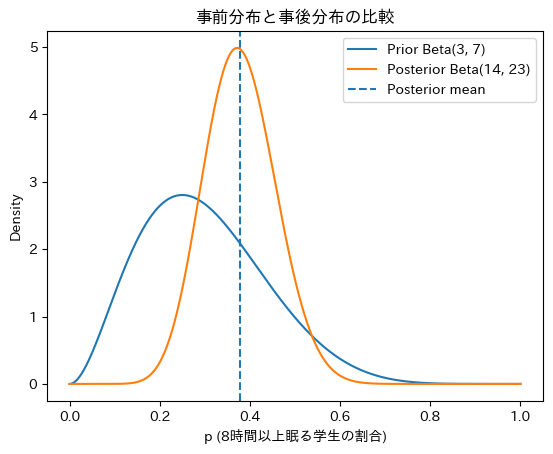

In [4]:
plt.figure()
plt.plot(p, prior_pdf, label="Prior Beta(3, 7)")
plt.plot(p, posterior_pdf, label="Posterior Beta(14, 23)")
plt.axvline(posterior_mean, linestyle="--", label="Posterior mean")

plt.xlabel("p (8時間以上眠る学生の割合)")
plt.ylabel("Density")
plt.title("事前分布と事後分布の比較")
plt.legend()
plt.show()


In [5]:
# 事後分布パラメータ
a_post = 14
b_post = 23

# 90%信用区間
lower, upper = beta.ppf([0.05, 0.95], a_post, b_post)

# 事後平均
posterior_mean = a_post / (a_post + b_post)

print("90%信用区間:")
print("Lower =", lower)
print("Upper =", upper)
print("事後平均 =", posterior_mean)


90%信用区間:
Lower = 0.2526516784406981
Upper = 0.5116834293432175
事後平均 = 0.3783783783783784


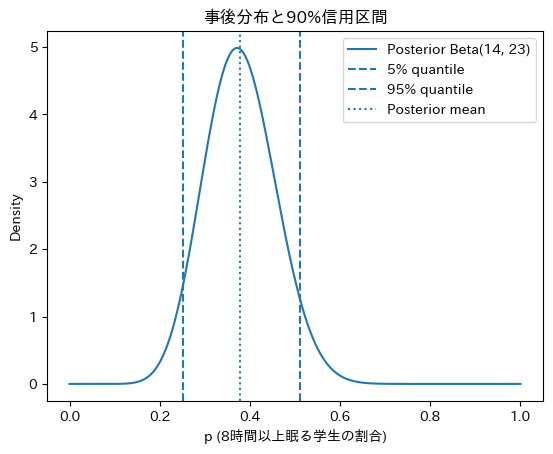

In [6]:
# p の範囲
p = np.linspace(0, 1, 1000)

# 事後分布
posterior_pdf = beta.pdf(p, a_post, b_post)

plt.figure()
plt.plot(p, posterior_pdf, label="Posterior Beta(14, 23)")

# 信用区間
plt.axvline(lower, linestyle="--", label="5% quantile")
plt.axvline(upper, linestyle="--", label="95% quantile")

# 事後平均
plt.axvline(posterior_mean, linestyle=":", label="Posterior mean")

plt.xlabel("p (8時間以上眠る学生の割合)")
plt.ylabel("Density")
plt.title("事後分布と90%信用区間")
plt.legend()
plt.show()


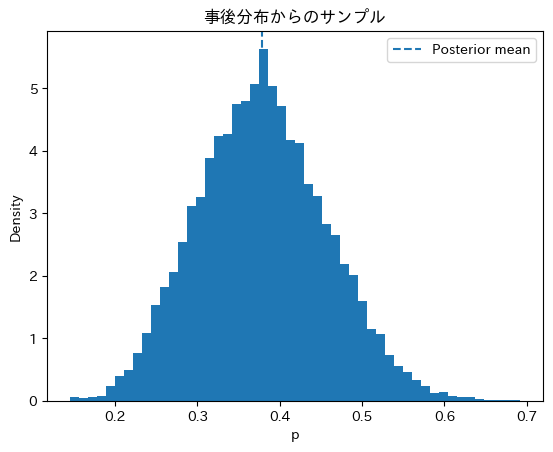

In [7]:
# 事後分布からサンプリング
samples = beta.rvs(a_post, b_post, size=10000)

plt.figure()
plt.hist(samples, bins=50, density=True)
plt.axvline(posterior_mean, linestyle="--", label="Posterior mean")

plt.xlabel("p")
plt.ylabel("Density")
plt.title("事後分布からのサンプル")
plt.legend()
plt.show()


また、別の大学生２０人を調査するとして、そのうち何人が８時間以上の睡眠をとっているかの予測も行う。

$ p | data \sim Beta(14,23) $

新しい調査

$ n_{new} = 20 $

8時間以上眠る人数 $ X $

予測するもの

$ P(X=k|data) $

$ X \sim BetaBinomial(n_{new}, a_{post}, b_{post}) $

In [8]:
# 事後分布パラメータ
a_post = 14
b_post = 23

# 新しい調査人数
n_new = 20

# 予測される成功数
k = np.arange(0, n_new + 1)

# 事後予測分布（Beta-Binomial）
pred_pmf = betabinom.pmf(k, n_new, a_post, b_post)

# 期待値と分散
pred_mean = n_new * a_post / (a_post + b_post)
pred_var = (n_new * a_post * b_post * (a_post + b_post + n_new)) / (
    (a_post + b_post)**2 * (a_post + b_post + 1)
)

print("予測される平均人数 =", pred_mean)
print("予測分散 =", pred_var)


予測される平均人数 = 7.5675675675675675
予測分散 = 7.056245434623813


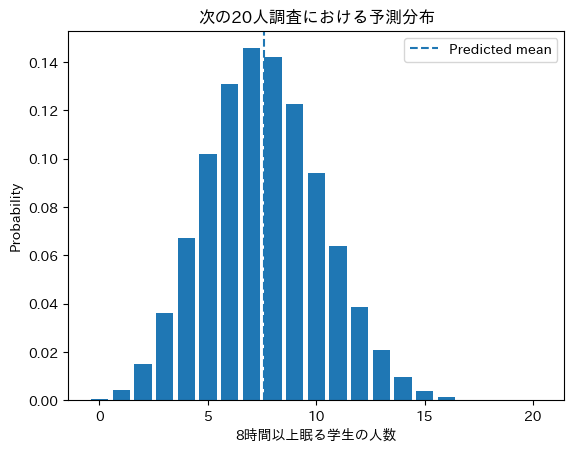

In [9]:
# 人数ごとの確率分布

plt.figure()
plt.bar(k, pred_pmf)
plt.axvline(pred_mean, linestyle="--", label="Predicted mean")

plt.xlabel("8時間以上眠る学生の人数")
plt.ylabel("Probability")
plt.title("次の20人調査における予測分布")
plt.legend()
plt.show()


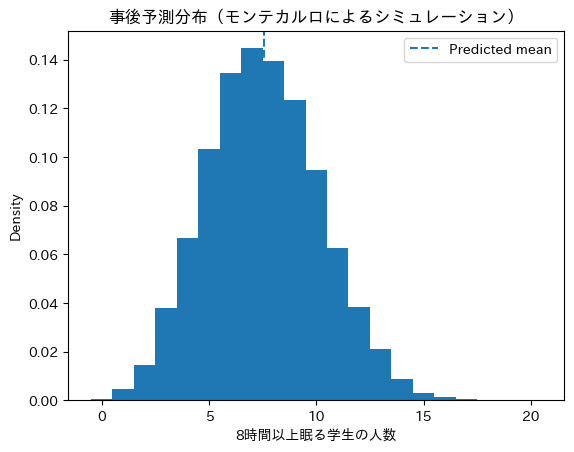

In [10]:
# シミュレーション回数
Nsim = 10000

# p を事後分布からサンプリング
p_samples = beta.rvs(a_post, b_post, size=Nsim)

# 各 p に対して20人調査を実施
x_samples = binom.rvs(n_new, p_samples)

plt.figure()
plt.hist(x_samples, bins=np.arange(-0.5, n_new+1.5), density=True)
plt.axvline(pred_mean, linestyle="--", label="Predicted mean")

plt.xlabel("8時間以上眠る学生の人数")
plt.ylabel("Density")
plt.title("事後予測分布（モンテカルロによるシミュレーション）")
plt.legend()
plt.show()


1. 離散事前分布の利用


離散的な確率と事前分布

p = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])

prior_weights = np.array([1, 5.2, 8, 7.2, 4.6, 2.1, 0.7, 0.1, 0, 0])

事前確率と事後確率を表すグラフの作成

In [11]:
p = np.array([0.05, 0.15, 0.25, 0.35, 0.45,
              0.55, 0.65, 0.75, 0.85, 0.95])
prior_weights = np.array([1, 5.2, 8, 7.2, 4.6,
                          2.1, 0.7, 0.1, 0, 0])

# 正規化して確率にする
prior = prior_weights / prior_weights.sum()

n = 27
s = 11

# 各 p に対する尤度
likelihood = binom.pmf(s, n, p)


In [12]:
# 非正規化事後分布
posterior_unnorm = likelihood * prior

# 正規化
posterior = posterior_unnorm / posterior_unnorm.sum()

for pi, pr, po in zip(p, prior, posterior):
    print(f"p={pi:.2f}, prior={pr:.3f}, posterior={po:.3f}")


p=0.05, prior=0.035, posterior=0.000
p=0.15, prior=0.180, posterior=0.002
p=0.25, prior=0.277, posterior=0.129
p=0.35, prior=0.249, posterior=0.477
p=0.45, prior=0.159, posterior=0.334
p=0.55, prior=0.073, posterior=0.056
p=0.65, prior=0.024, posterior=0.002
p=0.75, prior=0.003, posterior=0.000
p=0.85, prior=0.000, posterior=0.000
p=0.95, prior=0.000, posterior=0.000


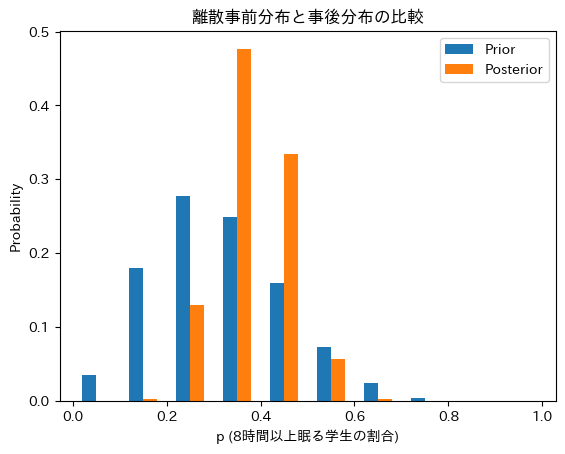

In [13]:
plt.figure()
plt.bar(p - 0.015, prior, width=0.03, label="Prior")
plt.bar(p + 0.015, posterior, width=0.03, label="Posterior")

plt.xlabel("p (8時間以上眠る学生の割合)")
plt.ylabel("Probability")
plt.title("離散事前分布と事後分布の比較")
plt.legend()
plt.show()


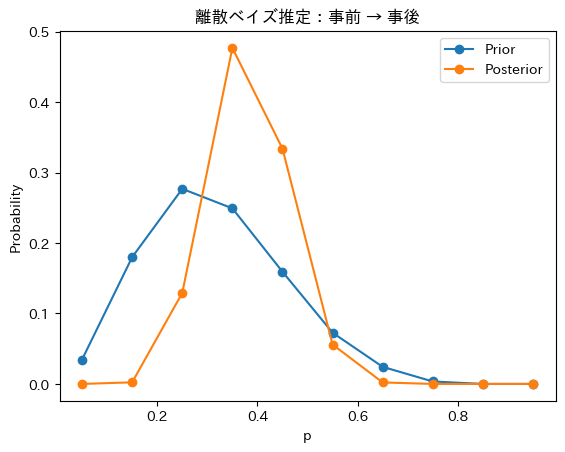

In [14]:
plt.figure()
plt.plot(p, prior, marker="o", label="Prior")
plt.plot(p, posterior, marker="o", label="Posterior")

plt.xlabel("p")
plt.ylabel("Probability")
plt.title("離散ベイズ推定：事前 → 事後")
plt.legend()
plt.show()


８時間睡眠をとった学生の割合をpで表す

pの事前密度 $ g(p) $

尤度関数(likdelifood function)

$ L(p) \propto p^s (1-p)^f \qquad (0 < p < 1) $
　
pの事後密度はベイズの法則で、比例定数を除くと、事前密度と尤度の積

$ g(p|data) \propto g(p)L(p) $

### 2.3 離散事前分布の利用

もっともらしい割合の値をリストアップし、これらの値に重みを与える。

それぞれの重みは全体の合計で割ることで、事前確率に変換できる。

二項分布はPMFは本来「X＝成功数」の確率分布

しかし、pを変数とみなすと「尤度関数」になる

この尤度を正規化するとベータ分布PDFになる


In [15]:
# データ
data = {'y':11, 'n':27}
y = data['y']
n = data['n']

# 離散的な確率と事前分布
p = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
prior_weights = np.array([1, 5.2, 8, 7.2, 4.6, 2.1, 0.7, 0.1, 0, 0])

# 正規化して事前確率に変換
prior = prior_weights / prior_weights.sum()

# 尤度 P(data | p)
likelihood = binom.pmf(y, n, p)

# 事後確率 ∝ prior × likelihood
posterior_unnorm = prior * likelihood
posterior = posterior_unnorm / posterior_unnorm.sum()

# 結果を表にまとめる
df = pd.DataFrame({
    "p": p,
    "prior": np.round(prior, 4),
    "posterior": np.round(posterior, 4)
})

print(df)


      p   prior  posterior
0  0.05  0.0346     0.0000
1  0.15  0.1799     0.0023
2  0.25  0.2768     0.1291
3  0.35  0.2491     0.4768
4  0.45  0.1592     0.3338
5  0.55  0.0727     0.0559
6  0.65  0.0242     0.0021
7  0.75  0.0035     0.0000
8  0.85  0.0000     0.0000
9  0.95  0.0000     0.0000


In [16]:
def pdisc(p, prior, data):

    p = np.array(p, dtype=float)
    prior = np.array(prior, dtype=float)

    y = data['y']
    n = data['n']

    likelihood = p**y*(1-p)**(n-y)

    unnormalized_post = likelihood * prior
    post = unnormalized_post/unnormalized_post.sum()
    
    return {'p': p, 'prior': prior, 'post': post}

In [17]:
df = pd.DataFrame(pdisc(p, prior, data))
df['prior'] = df['prior'].round(4)
df['post'] = df['post'].round(4)
df

,p,prior,post
0,0.05,0.0346,0.0000
1,0.15,0.1799,0.0023
2,0.25,0.2768,0.1291
3,0.35,0.2491,0.4768
4,0.45,0.1592,0.3338
5,0.55,0.0727,0.0559
6,0.65,0.0242,0.0021
7,0.75,0.0035,0.0000
8,0.85,0.0000,0.0000
9,0.95,0.0000,0.0000


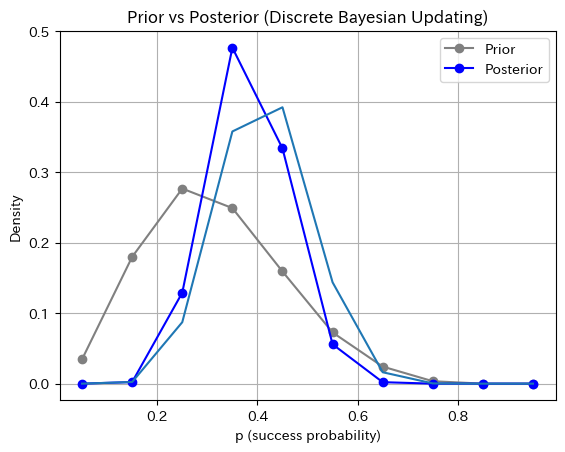

In [18]:
plt.plot(p, prior, 'o-', label='Prior', color='gray')
plt.plot(p, posterior, 'o-', label='Posterior', color='blue')
plt.plot(p, likelihood/likelihood.sum())
plt.xlabel("p (success probability)")
plt.ylabel("Density")
plt.title("Prior vs Posterior (Discrete Bayesian Updating)")
plt.legend()
plt.grid(True)
plt.show()


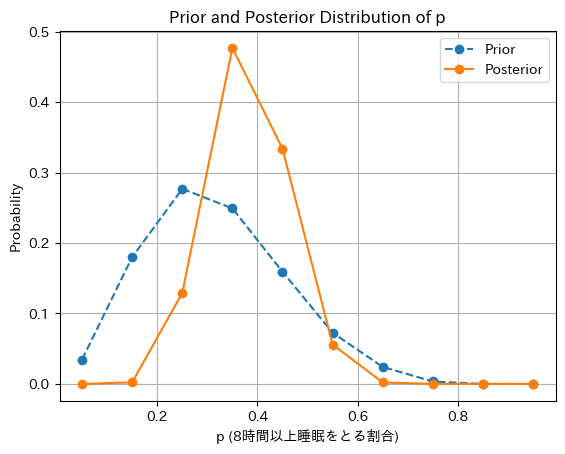

In [19]:
# 離散的なpの候補
p = np.array([0.05, 0.15, 0.25, 0.35, 0.45,
              0.55, 0.65, 0.75, 0.85, 0.95])

# 事前分布の重み
prior_weights = np.array([1, 5.2, 8, 7.2, 4.6,
                          2.1, 0.7, 0.1, 0, 0])

# 正規化して事前確率にする
prior = prior_weights / prior_weights.sum()

# 観測データ
n = 27   # 学生数
y = 11   # 8時間以上寝た人数

# 尤度（二項分布）
likelihood = binom.pmf(y, n, p)

# 事後分布（未正規化）
posterior_unnorm = prior * likelihood

# 正規化
posterior = posterior_unnorm / posterior_unnorm.sum()

# ===== グラフ =====
plt.figure()
plt.plot(p, prior, marker='o', linestyle='--', label='Prior')
plt.plot(p, posterior, marker='o', label='Posterior')
plt.xlabel('p (8時間以上睡眠をとる割合)')
plt.ylabel('Probability')
plt.title('Prior and Posterior Distribution of p')
plt.legend()
plt.grid(True)
plt.show()


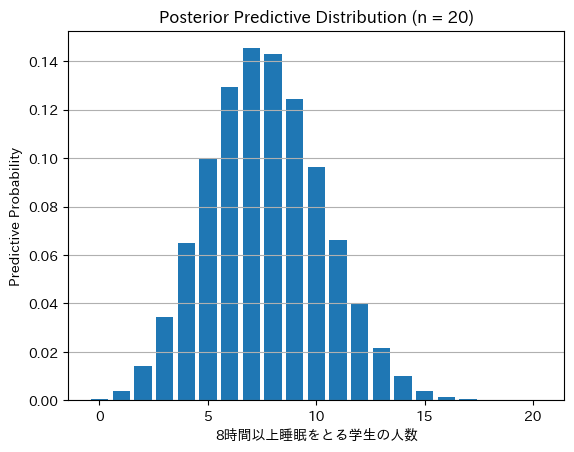

In [20]:
# ===== 事後予測分布 =====
m = 20                      # 新しい調査人数
k_vals = np.arange(m + 1)   # 0,1,...,20

predictive = np.zeros_like(k_vals, dtype=float)

for i, pi in enumerate(p):
    predictive += posterior[i] * binom.pmf(k_vals, m, pi)

# ===== グラフ =====
plt.figure()
plt.bar(k_vals, predictive)
plt.xlabel('8時間以上睡眠をとる学生の人数')
plt.ylabel('Predictive Probability')
plt.title('Posterior Predictive Distribution (n = 20)')
plt.grid(axis='y')
plt.show()


### 2.9.1 練習問題

ボブは自分には超感覚的視覚（ESP）があると主張している。
事実かどうか確かめるため、あなたは次のような実験を行おうとしている。
異なる幾何学図形が描かれた４枚の大型カードからあなたが１枚を選択する。
その図柄をボブが当てようとするのである。
ボブが１枚のカードの図柄を正しく言い当てる確率をpとおくとしよう。
あなたはボブには超感覚的知覚能力などないと考えているが（$ p=0.25 $）、それでも p が0.２５よりも大きかったり小さかったりする可能性もわずかながら残される。
そこで考えた結果、pの事前分布を次のようにおくとする。

さて、実験は１０回繰り返され、そのうちボブの正解は６回、不正解は４回であるとしよう。
pの各値の事後確率を求めよ。
ボブに超感覚的知覚能力などないとする事後確率はいくらであろうか。

In [21]:
# データ
data = {'y':6, 'n':10}
y = data['y']
n = data['n']

# 離散的な確率と事前分布
p = np.array([0, 0.125, 0.250, 0.375, 0.500, 0.625, 0.750, 0.875, 1])
prior_weights = np.array([0.001, 0.001, 0.950, 0.008, 0.008, 0.008, 0.008, 0.008, 0.008])

# 正規化して事前確率に変換
prior = prior_weights / prior_weights.sum()

In [22]:
# 尤度 P(data | p)
likelihood = binom.pmf(y, n, p)

# 事後確率 ∝ prior × likelihood
posterior_unnorm = prior * likelihood
posterior = posterior_unnorm / posterior_unnorm.sum()

# 結果を表にまとめる
df = pd.DataFrame({
    "p": p,
    "prior": np.round(prior, 4),
    "posterior": np.round(posterior, 4)
})

print(df)

       p  prior  posterior
0  0.000  0.001     0.0000
1  0.125  0.001     0.0000
2  0.250  0.950     0.7305
3  0.375  0.008     0.0338
4  0.500  0.008     0.0778
5  0.625  0.008     0.0939
6  0.750  0.008     0.0554
7  0.875  0.008     0.0087
8  1.000  0.008     0.0000


In [23]:
# --- 事前分布 ---
p = np.array([0, 0.125, 0.250, 0.375, 0.500, 0.625, 0.750, 0.875, 1])
prior_weights = np.array([0.001, 0.001, 0.950, 0.008, 0.008, 0.008, 0.008, 0.008, 0.008])

# --- 観測データ ---
k = 6  # 正解数
n = 10 # 試行回数

# --- 尤度 L(p | data) ---
likelihood = p**k * (1 - p)**(n - k)

# --- 事後分布 posterior ∝ prior × likelihood ---
unnormalized_posterior = prior_weights * likelihood
posterior = unnormalized_posterior / unnormalized_posterior.sum()

print("各 p の事後確率:")
for pi, post in zip(p, posterior):
    print(f"p = {pi:.3f}: {post:.6f}")

# --- p = 0.25（超感覚なし）の事後確率 ---
posterior_no_esp = posterior[p == 0.25][0]
print("\nボブには超感覚的知覚能力などない (p = 0.25) の事後確率:", posterior_no_esp)


各 p の事後確率:
p = 0.000: 0.000000
p = 0.125: 0.000022
p = 0.250: 0.730473
p = 0.375: 0.033790
p = 0.500: 0.077765
p = 0.625: 0.093862
p = 0.750: 0.055362
p = 0.875: 0.008725
p = 1.000: 0.000000

ボブには超感覚的知覚能力などない (p = 0.25) の事後確率: 0.7304727187534582


### 2.4 ベータ事前分布の利用

研究者は $ p $ として 0.3 を中心にその前後の値を想定している。（平均が0.3）

さらに、$ p $ は、0.5 より小さいという 90% の確信を抱いているものとする。

In [24]:
from scipy.optimize import root_scalar

# 平均条件から b を a の関数として定義
def b_from_a(a):
    return (7/3) * a

# 確率条件 P(p < 0.5) = 0.9
def equation(a):
    b = b_from_a(a)
    return beta.cdf(0.5, a, b) - 0.9

# 数値解を探す（a > 0）
solution = root_scalar(equation, bracket=[0.1, 100], method="bisect")

a_est = solution.root
b_est = b_from_a(a_est)

print("推定された事前分布パラメータ")
print("a =", a_est)
print("b =", b_est)

# 確認
print("平均 =", a_est / (a_est + b_est))
print("P(p < 0.5) =", beta.cdf(0.5, a_est, b_est))


推定された事前分布パラメータ
a = 2.7107102882605583
b = 6.32499067260797
平均 = 0.3
P(p < 0.5) = 0.8999999999999679


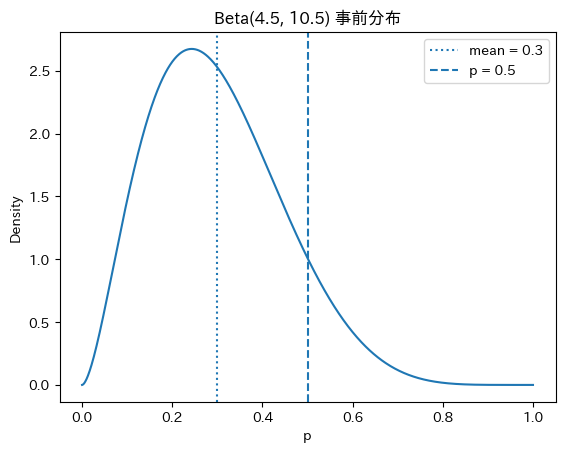

In [25]:
p = np.linspace(0, 1, 1000)
prior_pdf = beta.pdf(p, a_est, b_est)

plt.figure()
plt.plot(p, prior_pdf)
plt.axvline(0.3, linestyle=":", label="mean = 0.3")
plt.axvline(0.5, linestyle="--", label="p = 0.5")

plt.xlabel("p")
plt.ylabel("Density")
plt.title("Beta(4.5, 10.5) 事前分布")
plt.legend()
plt.show()


研究者が、事前分布の中央値と９０％分位点がそれぞれ0.3と0.5であるとした場合はどうなりますか（中央値が0.3）

In [26]:
from scipy.optimize import root

# 条件式
def equations(params):
    a, b = params
    eq1 = beta.cdf(0.3, a, b) - 0.5   # 中央値
    eq2 = beta.cdf(0.5, a, b) - 0.9   # 90%分位点
    return [eq1, eq2]

# 初期値（正の値を与える）
initial_guess = [4, 10]

solution = root(equations, initial_guess)

a_est, b_est = solution.x

print("推定された事前分布パラメータ")
print("a =", a_est)
print("b =", b_est)

# 検算
print("CDF(0.3) =", beta.cdf(0.3, a_est, b_est))
print("CDF(0.5) =", beta.cdf(0.5, a_est, b_est))
print("平均 =", a_est / (a_est + b_est))


推定された事前分布パラメータ
a = 3.2637446805128496
b = 7.185125237065671
CDF(0.3) = 0.5000000000000405
CDF(0.5) = 0.9000000000000615
平均 = 0.312353843646013


In [27]:
from scipy.optimize import minimize

def beta_select(q1, q2):
    p1, x1 = q1["p"], q1["x"]
    p2, x2 = q2["p"], q2["x"]

    # 目的関数（誤差の2乗和）
    def objective(params):
        a, b = params

        # ベータ分布の分位点の差
        diff1 = beta.ppf(p1, a, b) - x1
        diff2 = beta.ppf(p2, a, b) - x2
        return diff1**2 + diff2**2
    
    # 初期値
    initial_guess = [2.0, 2.0]

    # 正のパラメータに制限
    bounds = [(1e-6, None), (1e-6, None)]

    result = minimize(objective, initial_guess, bounds=bounds)
    a_est, b_est, = result.x

    return a_est, b_est



In [28]:
q1 = {"p": 0.5, "x":0.3}
q2 = {"p": 0.9, "x":0.5}

a, b = beta_select(q1, q2)

print(f"{a:.2f}")
print(f"{b:.2f}")

3.27
7.19


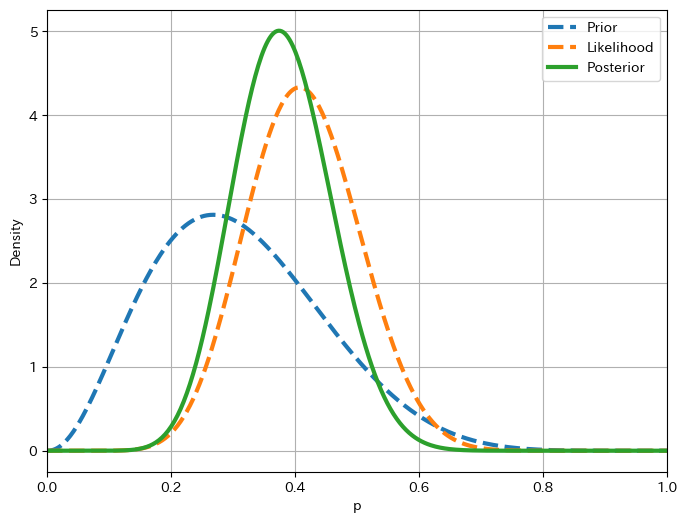

In [29]:
s = 11
f = 16

x = np.linspace(0,1,400)

# Prior 
prior = beta.pdf(x, a, b)

# Likelihood
likelihood = beta.pdf(x, s+1, f+1)

# Posterior
posterior = beta.pdf(x, a+s, b+f)

# Plot
plt.figure(figsize=(8,6))
plt.plot(x, prior, linestyle='--', linewidth=3, label='Prior')
plt.plot(x, likelihood, linestyle='--', linewidth=3, label="Likelihood")
plt.plot(x, posterior, linestyle='-', linewidth=3, label='Posterior')

plt.xlim(0,1)
plt.xlabel("p")
plt.ylabel("Density")
plt.legend(loc='upper right')
plt.grid(True)


In [30]:
result = 1 - beta.cdf(0.5, a+s, b+f)
print(f'result = {result:.8f}')

lower = beta.ppf(0.05, a+s, b+f)
upper = beta.ppf(0.95, a+s, b+f)

print(f"lower = {lower:.2f} upper = {upper:.2f}")

result = 0.06919156
lower = 0.26 upper = 0.51


5% 分位点：0.25 95% 分位点：0.51


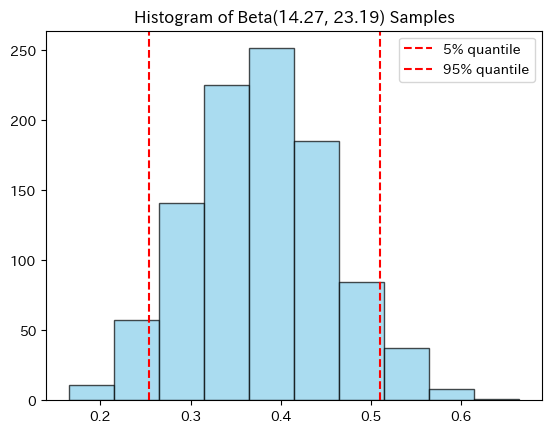

In [31]:
alpha = a + s
beta_param = b + f

samples = beta.rvs(alpha, beta_param, size=1000)

q5 = np.percentile(samples, 5)
q95 = np.percentile(samples, 95)

print(f'5% 分位点：{q5:.2f} 95% 分位点：{q95:.2f}')

plt.hist(samples, bins= 10, density=False, alpha=0.7, color="skyblue", edgecolor="black")
plt.title(f"Histogram of Beta({alpha:.2f}, {beta_param:.2f}) Samples")
plt.axvline(q5, color="red", linestyle="--", label="5% quantile")
plt.axvline(q95, color="red", linestyle="--", label="95% quantile")
plt.legend()

### ヒストグラム事前分布の利用

研究者が睡眠時間が足りている学生の割合についての事前の確信を表現するのに、便宜上、p の範囲を１０個の部分区間 (0,0.1),(0.1,0.2),..,(0.9,1) に分割し、それぞれの区間に確率を割り当てるとし、その区間に prior_weights = np.array([1, 5.2, 8, 7.2, 4.6, 2.1, 0.7, 0.1, 0, 0]) を重みとして割り当てる。

1. 割合 p をヒストグラム事前密度として描画せよ。

2. p のグリッド上で、ヒストグラム事前密度と尤度関数を乗じて事後密度を計算し、描画せよ。
ただし、ベータ密度　likelihood = beta.pdf(x, s+1, f+1)　s = 11, f = 16。

3. 新たに、m=20 人の学生を調査するとして、そのうち何人が十分な睡眠をとっているか、その数 $ \bar{y} $ の予測を行え。

In [32]:
midpt = np.arange(0.05, 1.0, 0.1)
prior_weights = np.array([1, 5.2, 8, 7.2, 4.6, 2.1, 0.7, 0.1, 0, 0])

# 正規化して事前確率に変換
prior = prior_weights / prior_weights.sum()
df = pd.DataFrame({'midpt': midpt, 'prior': prior})
df

,midpt,prior
0,0.05,0.034602
1,0.15,0.179931
2,0.25,0.276817
3,0.35,0.249135
4,0.45,0.159170
5,0.55,0.072664
6,0.65,0.024221
7,0.75,0.003460
8,0.85,0.000000
9,0.95,0.000000


Rのhistprior()は、多くのベイズ入門資料で使われる**教育用の関数**

* y軸：Probability
* 角棒の高さ：区間確率
* 棒の和：１

人間の直感を優先した表示になっている。

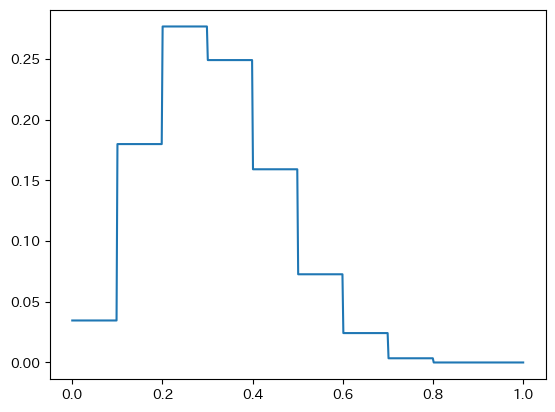

In [33]:
def histprior(x, midpt, prior):
    dx_mid = np.diff(midpt)
    dx_mid = np.append(dx_mid, dx_mid[-1])
    
    left = midpt - dx_mid/2
    right = midpt + dx_mid/2

    y = np.zeros_like(x)
    for l, r, p, w in zip(left, right, prior, dx_mid):
        y += ((x>=l)&(x<r))*(p/w)

    y[x==1]=prior[-1]/dx_mid[-1]
    y = y*dx_mid[0]

    return y


x = np.linspace(0,1,500)
y = histprior(x, midpt, prior)

plt.plot(x,y,label="Prior density")


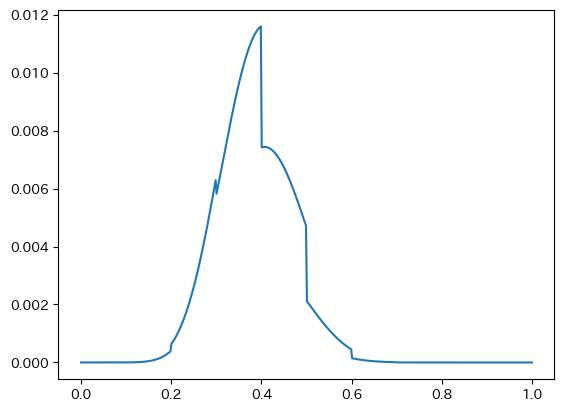

In [34]:
# Likelihood
likelihood = beta.pdf(x, s+1, f+1)

posterior = y*likelihood/np.sum(y*likelihood)

plt.plot(x, posterior/posterior.sum(), label="Posterior density")

Text(0.5, 1.0, '図2.7 ヒストグラム事前密度を利用したpの事後分布からシュミレーションした表本のヒストグラム')

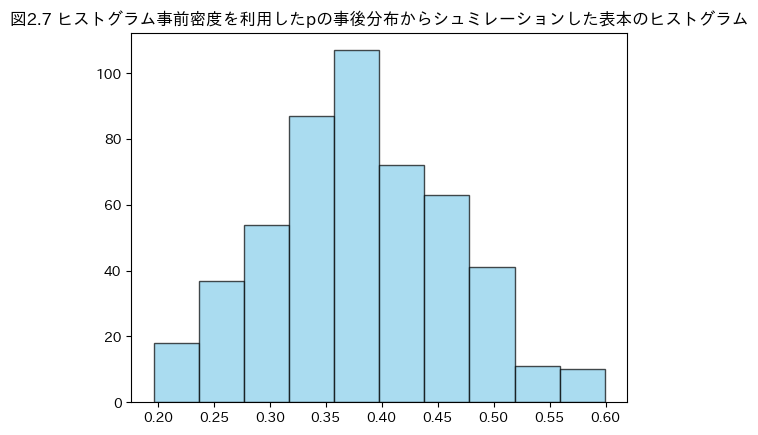

In [35]:
p = np.linspace(0,1,500)

sample = np.random.choice(p, size=500, replace=True, p=posterior)

plt.hist(sample, bins=10, density=False, alpha=0.7, color="skyblue", edgecolor="black")
plt.title("図2.7 ヒストグラム事前密度を利用したpの事後分布からシュミレーションした表本のヒストグラム")

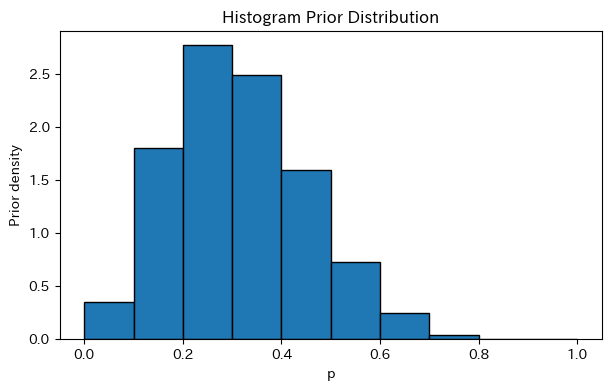

AttributeError: module 'numpy' has no attribute 'trapezoid'

In [36]:
# ==============================
# 事前分布（ヒストグラム）
# ==============================
bins = np.linspace(0, 1, 11)        # 10区間
bin_centers = (bins[:-1] + bins[1:]) / 2

prior_weights = np.array([1, 5.2, 8, 7.2, 4.6, 2.1, 0.7, 0.1, 0, 0])

# 正規化（確率密度として扱う）
prior_probs = prior_weights / prior_weights.sum()
bin_width = bins[1] - bins[0]
prior_density = prior_probs / bin_width

# ==============================
# 1. ヒストグラム事前密度の描画
# ==============================
plt.figure(figsize=(7,4))
plt.bar(bin_centers, prior_density, width=bin_width,
        edgecolor='black', align='center')
plt.xlabel("p")
plt.ylabel("Prior density")
plt.title("Histogram Prior Distribution")
plt.show()

# ==============================
# 2. 事後密度の計算と描画
# ==============================
# p のグリッド
x = np.linspace(0, 1, 1000)

# 尤度（Beta密度）
s, f = 11, 16
likelihood = beta.pdf(x, s + 1, f + 1)

# ヒストグラム事前密度をグリッド上に展開
prior_grid = np.zeros_like(x)
for i in range(len(prior_density)):
    mask = (x >= bins[i]) & (x < bins[i+1])
    prior_grid[mask] = prior_density[i]

# 事後（未正規化）
posterior_unnorm = prior_grid * likelihood

# 正規化
posterior = posterior_unnorm / np.trapezoid(posterior_unnorm, x)

# ==============================
# 描画
# ==============================
plt.figure(figsize=(7,4))
plt.plot(x, posterior, label="Posterior density")
plt.plot(x, likelihood / np.trapezoid(likelihood, x),
         linestyle='--', label="Likelihood (scaled)")
plt.bar(bin_centers, prior_density,
        width=bin_width, alpha=0.3, label="Prior (histogram)")
plt.xlabel("p")
plt.ylabel("Density")
plt.title("Posterior from Histogram Prior")
plt.legend()
plt.show()


In [ ]:
# 正規化（区間確率）
prior_probs = prior_weights / prior_weights.sum()

# ヒストグラム事前密度
prior_density = np.zeros_like(x)

for i in range(10):
    mask = (x >= 0.1*i) & (x < 0.1*(i+1))
    prior_density[mask] = prior_probs[i] / 0.1


In [ ]:
m = 20
k_vals = np.arange(m+1)

predictive = np.zeros_like(k_vals, dtype=float)

for i, k in enumerate(k_vals):
    pmf = binom.pmf(k, m, x)
    predictive[i] = np.trapezoid(pmf * posterior, x)

# 正規化（数値誤差対策）
predictive /= predictive.sum()


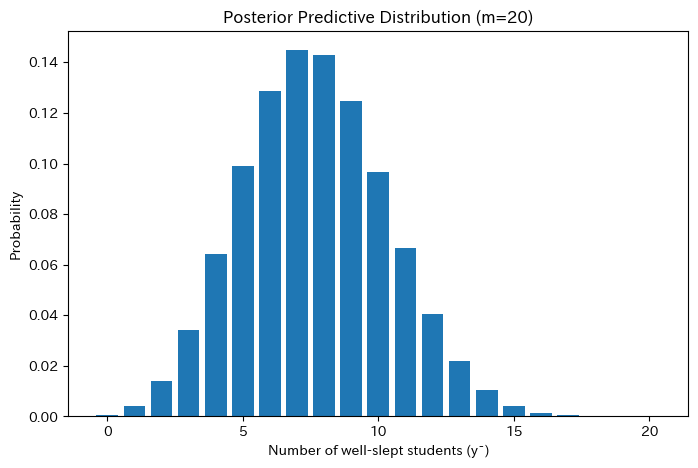

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(k_vals, predictive)
plt.xlabel("Number of well-slept students (ȳ)")
plt.ylabel("Probability")
plt.title("Posterior Predictive Distribution (m=20)")
plt.show()


In [ ]:
m = 20
k_vals = np.arange(m+1)

predictive = np.zeros_like(k_vals, dtype=float)

for i, k in enumerate(k_vals):
    pmf = binom.pmf(k, m, x)
    predictive[i] = np.trapezoid(pmf * posterior, x)

# 正規化（数値誤差対策）
predictive /= predictive.sum()


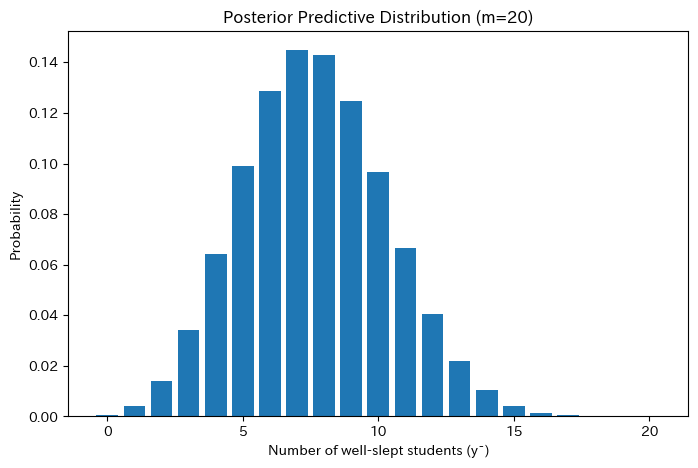

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(k_vals, predictive)
plt.xlabel("Number of well-slept students (ȳ)")
plt.ylabel("Probability")
plt.title("Posterior Predictive Distribution (m=20)")
plt.show()


### 2.9.2 練習問題

硬貨を机などの硬い平面上に立て、指で回転させる。
硬貨が倒れた時に表が出る確率をpとする。
この確率を推定するため、ヒストグラムを使ってpについて事前に抱いている確率をモデル化する。
区間（0,1）を１０個の小区間(0,0.1)(0.1,0.2)..(0.9,1)に分割する。
そしてpが各小区間になる確率をそれぞれ割り当てる。
続いて硬貨を２０回回転させて成功（表）と失敗（裏）の回数を数える。
次の手順で事後分布をシュミレーションする。
（１）区間(0,1)上の値のグリッドでpの事後密度を計算する。
（２）グリッドから置き換えありのシュミレーション標本を集める。
データに基づくと各区間の確率はどのように変わっただろうか？

各小区間の事後確率：
(0.0, 0.1) : 0.0000
(0.1, 0.2) : 0.0000
(0.2, 0.3) : 0.0003
(0.3, 0.4) : 0.0094
(0.4, 0.5) : 0.0769
(0.5, 0.6) : 0.2563
(0.6, 0.7) : 0.3872
(0.7, 0.8) : 0.2361
(0.8, 0.9) : 0.0336
(0.9, 1.0) : 0.0001

シミュレーションによる事後区間確率：
(0.0, 0.1) : 0.0000
(0.1, 0.2) : 0.0000
(0.2, 0.3) : 0.0008
(0.3, 0.4) : 0.0119
(0.4, 0.5) : 0.0847
(0.5, 0.6) : 0.2553
(0.6, 0.7) : 0.3761
(0.7, 0.8) : 0.2291
(0.8, 0.9) : 0.0414
(0.9, 1.0) : 0.0007


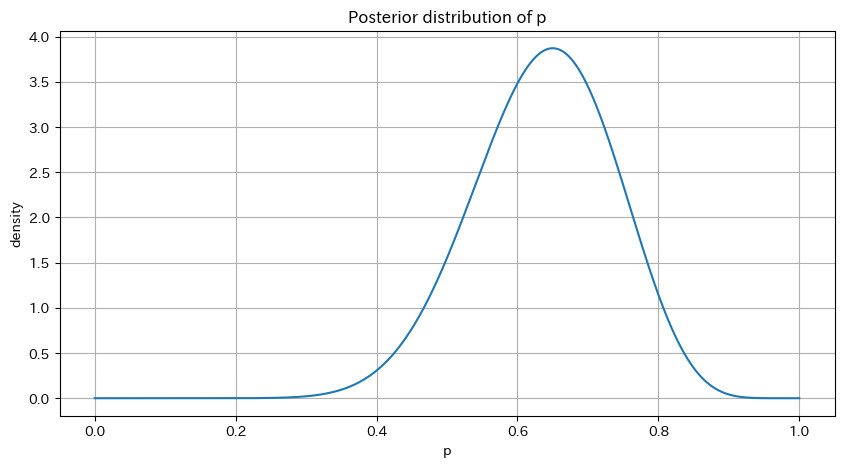

In [ ]:
# ---- 1. 区間設定 ----
bins = np.linspace(0, 1, 11)  # 10 区間 → 11 境界
bin_centers = (bins[:-1] + bins[1:]) / 2  # 小区間の中心点（事後計算用 p 値）

# 事前分布（例：一様）
prior = np.ones(10) / 10  

# ---- 2. 観測データ（必要に応じて変更） ----
n = 20
k = 13  # 成功数

# ---- 3. 小区間中心を使って尤度計算 ----
likelihood = bin_centers**k * (1 - bin_centers)**(n - k)

# ---- 4. 離散事後分布（小区間単位） ----
unnorm_post = prior * likelihood
posterior = unnorm_post / unnorm_post.sum()

print("各小区間の事後確率：")
for i in range(10):
    print(f"({bins[i]:.1f}, {bins[i+1]:.1f}) : {posterior[i]:.4f}")

# ---- 5. グリッドでの事後密度を計算 ----
grid_p = np.linspace(0, 1, 2000)
grid_prior = np.interp(grid_p, bin_centers, prior)  # ヒストグラム事前を補間
grid_likelihood = grid_p**k * (1 - grid_p)**(n - k)
grid_posterior = grid_prior * grid_likelihood
grid_posterior /= np.trapezoid(grid_posterior, grid_p)  # 正規化

# ---- 6. 事後分布からのシミュレーション ----
Nsim = 50000
posterior_samples = np.random.choice(grid_p, size=Nsim, p=grid_posterior/ grid_posterior.sum())

# ---- 7. サンプルから区間別の確率を再計算 ----
sim_posterior_hist, _ = np.histogram(posterior_samples, bins=bins, density=True)
sim_posterior_prob = sim_posterior_hist * np.diff(bins)

print("\nシミュレーションによる事後区間確率：")
for i in range(10):
    print(f"({bins[i]:.1f}, {bins[i+1]:.1f}) : {sim_posterior_prob[i]:.4f}")

# ---- optional: プロット ----
plt.figure(figsize=(10,5))
plt.plot(grid_p, grid_posterior, label="Posterior density")
plt.xlabel("p")
plt.ylabel("density")
plt.title("Posterior distribution of p")
plt.grid(True)
plt.show()



二項分布による事前分布：
(0.0, 0.1) : 0.0020
(0.1, 0.2) : 0.0176
(0.2, 0.3) : 0.0703
(0.3, 0.4) : 0.1641
(0.4, 0.5) : 0.2461
(0.5, 0.6) : 0.2461
(0.6, 0.7) : 0.1641
(0.7, 0.8) : 0.0703
(0.8, 0.9) : 0.0176
(0.9, 1.0) : 0.0020

離散区間の事後分布：
(0.0, 0.1) : 0.0000
(0.1, 0.2) : 0.0000
(0.2, 0.3) : 0.0001
(0.3, 0.4) : 0.0094
(0.4, 0.5) : 0.1152
(0.5, 0.6) : 0.3840
(0.6, 0.7) : 0.3867
(0.7, 0.8) : 0.1010
(0.8, 0.9) : 0.0036
(0.9, 1.0) : 0.0000

シミュレーションによる事後区間確率：
(0.0, 0.1) : 0.0000
(0.1, 0.2) : 0.0000
(0.2, 0.3) : 0.0003
(0.3, 0.4) : 0.0131
(0.4, 0.5) : 0.1216
(0.5, 0.6) : 0.3650
(0.6, 0.7) : 0.3748
(0.7, 0.8) : 0.1175
(0.8, 0.9) : 0.0076
(0.9, 1.0) : 0.0000


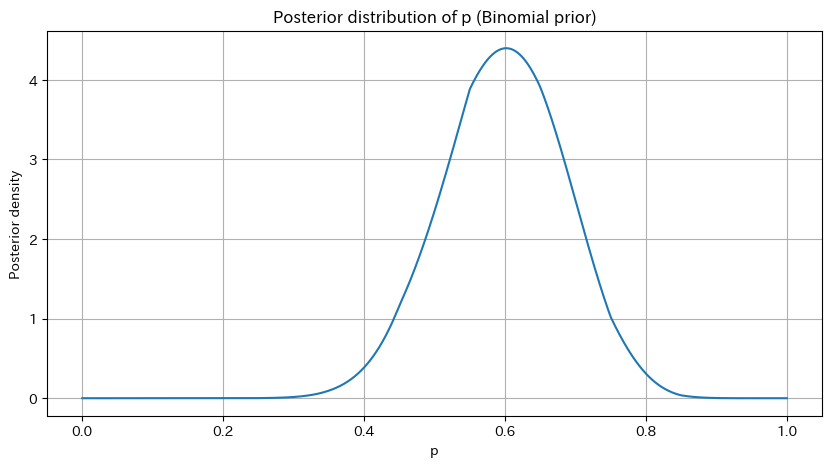

In [ ]:
# ---- 1. 区間設定 ----
bins = np.linspace(0, 1, 11)  # 10 区間
bin_centers = (bins[:-1] + bins[1:]) / 2

# ---- 事前分布：Binomial(n=9, p=0.5) ----
prior = binom.pmf(np.arange(10), n=9, p=0.5)
prior /= prior.sum()

print("二項分布による事前分布：")
for i in range(10):
    print(f"({bins[i]:.1f}, {bins[i+1]:.1f}) : {prior[i]:.4f}")

# ---- 2. 観測データ ----
n = 20
k = 13  # 成功回数

# ---- 3. 尤度 ----
likelihood = bin_centers**k * (1 - bin_centers)**(n - k)

# ---- 4. 離散事後分布 ----
unnorm_post = prior * likelihood
posterior = unnorm_post / unnorm_post.sum()

print("\n離散区間の事後分布：")
for i in range(10):
    print(f"({bins[i]:.1f}, {bins[i+1]:.1f}) : {posterior[i]:.4f}")

# ---- 5. グリッド上での連続事後密度 ----
grid_p = np.linspace(0, 1, 2000)

# 事前をグリッドに線形補間
grid_prior = np.interp(grid_p, bin_centers, prior)

grid_likelihood = grid_p**k * (1 - grid_p)**(n - k)
grid_posterior = grid_prior * grid_likelihood
grid_posterior /= np.trapezoid(grid_posterior, grid_p)

# ---- 6. 事後からのシミュレーション ----
Nsim = 50000
posterior_samples = np.random.choice(grid_p, size=Nsim,
                                     p=grid_posterior / grid_posterior.sum())

# ---- 7. サンプルから区間別確率を再推定（←修正箇所） ----
sim_hist, _ = np.histogram(posterior_samples, bins=bins, density=True)
sim_posterior_prob = sim_hist * np.diff(bins)

print("\nシミュレーションによる事後区間確率：")
for i in range(10):
    print(f"({bins[i]:.1f}, {bins[i+1]:.1f}) : {sim_posterior_prob[i]:.4f}")

# ---- optional plot ----
plt.figure(figsize=(10,5))
plt.plot(grid_p, grid_posterior)
plt.xlabel("p")
plt.ylabel("Posterior density")
plt.title("Posterior distribution of p (Binomial prior)")
plt.grid(True)
plt.show()


### 予測

新たにm=20人の学生を調査するとして、そのうち何人が十分な睡眠をとっているか、その $ \bar{y} $ の予測も行いたい。

In [ ]:
p = np.arange(0.05, 1, 0.1)

prior_weights = np.array([1, 5.2, 8, 7.2, 4.6, 2.1, 0.7, 0.1, 0, 0])

# 正規化して事前確率に変換
prior = prior_weights / prior_weights.sum()

m = 20
ys =np.arange(0,21)

pred = np.zeros_like(ys, dtype=float)

for i, y in enumerate(ys):
    pred[i] = np.sum(binom.pmf(y,m,p)*prior)

result = np.column_stack((ys, np.round(pred,3)))
df = pd.DataFrame({"y":ys, "pred":pred.round(3)})
df


,y,pred
0,0,0.020
1,1,0.044
2,2,0.069
3,3,0.092
4,4,0.106
5,5,0.112
6,6,0.110
7,7,0.102
8,8,0.089
9,9,0.074


Text(0.5, 0, 'y')

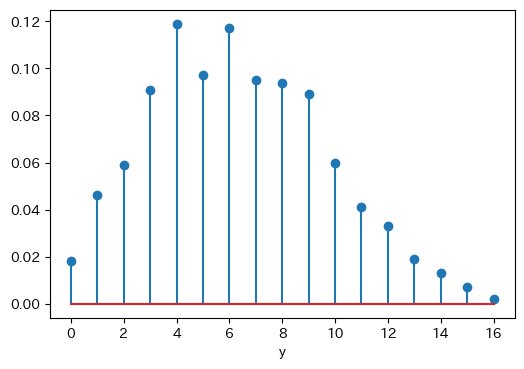

In [ ]:
# --- パラメータ
ab = (3.26, 7.19)
m = 20
ys = np.arange(0,21)

a, b = ab

# ベータ・ビノム予測分布
pred =betabinom.pmf(ys, m, a, b)

# 予測サンプルの生成
p = beta.rvs(a,b,size=1000)
y = binom.rvs(m,p)

ys_freq, counts = np.unique(y, return_counts=True)
predprob = counts/counts.sum()

df = pd.DataFrame({"freq":ys_freq, "counts":counts})


plt.figure(figsize=(6,4))
plt.stem(ys_freq, predprob)
plt.xlabel("y")

In [ ]:
def discint(ys, probs, covprob=0.9):
    idx = np.argsort(-probs)
    ys_sorted = ys[idx]
    probs_sorted = probs[idx]
    cumlative = np.cumsum(probs_sorted)
    k = np.searchsorted(cumlative, covprob)+1

    hpd_set = ys_sorted[:k]

    interval = (hpd_set.min(), hpd_set.max())

    return {
        "set": np.array(sorted(hpd_set)),
        "interval": np.array(interval),
        "coverage": np.array(probs_sorted[:k].sum())
    }    

In [ ]:
covprob = 0.9
result = discint(ys, pred, covprob)
result

{'set': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]),
 'interval': array([ 1, 11]),
 'coverage': array(0.90712913)}

### 2.9.3 練習問題

幼少期に低水準の鉛にされされたことが長期にわたって及ぼす影響について報告した。
研究者は子供のの抜け落ちた乳歯を分析して、鉛の含有量を調べた。
乳歯に22.22ppm以上の鉛が含まれていた子供のうち、22人が最終的には高校を卒業し、7人が卒業しなかった。
ここで、高校を卒業するこのような子供たち全ての割合pの事前密度がベータ分布 beta(1,1) であるとすると、事後密度は beta(23,8) である。

(a) pの90%区間を推定せよ。

(b) pが0.6を超える確率を計算せよ。

(c) pの事後分布から1000個のシュミレーション標本を取り出せ。

(d) 鉛の含有量が22.22ppmよりも多い子供がさらに10人いるとする。このうち高校を卒業するのが9人ないし10人となる予測確率を求めよ。予測分布からシュミレーション標本を抽出する。

In [ ]:
from scipy.special import beta as beta_func

# 事後分布パラメータ
a_post = 23
b_post = 8

print("Posterior = Beta(23, 8)\n")

# ---------------------------
# (a) p の 90% 区間（90% credible interval）
# ---------------------------
ci_90 = beta.ppf([0.05, 0.95], a_post, b_post)
print("(a) 90% Credible Interval:", ci_90)

# ---------------------------
# (b) P(p > 0.6)
# ---------------------------
prob_p_gt_06 = 1 - beta.cdf(0.6, a_post, b_post)
print("(b) P(p > 0.6) =", prob_p_gt_06)

# ---------------------------
# (c) 事後分布から 1000 個のシミュレーション標本
# ---------------------------
samples = beta.rvs(a_post, b_post, size=1000)
print("(c) 事後分布からのシミュレーション標本（最初の10個）:\n", samples[:10])

# ---------------------------
# (d) 予測分布：
#     10 人中の卒業者数の予測分布
#     P(Y = 9) + P(Y = 10)
# ---------------------------

# 予測分布はベータ・ビノム分布：
# P(Y = k | data) = C(10, k) * Beta(a_post + k, b_post + 10 - k) / Beta(a_post, b_post)

def beta_binom_pmf(k, n, a, b):
    # 組合せ C(n,k)
    comb = binom.pmf(k, n, 0.5) / (0.5**k * 0.5**(n-k))
    # ベータ関数を使って PMF を計算
    return comb * beta_func(a + k, b + n - k) / beta_func(a, b)

n_pred = 10

# P(Y=9)
p_y9 = beta_binom_pmf(9, n_pred, a_post, b_post)
# P(Y=10)
p_y10 = beta_binom_pmf(10, n_pred, a_post, b_post)

print("\n(d) P(Y=9) =", p_y9)
print("    P(Y=10) =", p_y10)
print("    P(Y=9 or 10) =", p_y9 + p_y10)

# シミュレーションによる予測分布
Nsim = 50000
sim_p = beta.rvs(a_post, b_post, size=Nsim)
sim_y = np.random.binomial(n_pred, sim_p)

prob_sim = np.mean((sim_y == 9) | (sim_y == 10))
print("    シミュレーション推定 P(Y=9 or 10) =", prob_sim)


Posterior = Beta(23, 8)

(a) 90% Credible Interval: [0.60605258 0.8598149 ]
(b) P(p > 0.6) = 0.956475881003445
(c) 事後分布からのシミュレーション標本（最初の10個）:
 [0.77151314 0.79599879 0.69373842 0.68944321 0.71501064 0.70118929
 0.74607584 0.73118996 0.65887583 0.80633731]

(d) P(Y=9) = 0.19026555404264398
    P(Y=10) = 0.07610622161705752
    P(Y=9 or 10) = 0.2663717756597015
    シミュレーション推定 P(Y=9 or 10) = 0.26574


### 2.9.4 練習問題

二人の人物が別々に、ある大学で公共の交通機関を使って通学している学生の割合Pを推測したいとする。ジョーの方は次の表に基づく離散事前確率を利用しようとしよう。

一方、サムの方は割合pについて、ベータ事前分布 beta(3,12) を利用することにする。

1. ジョーとサムのそれぞれ事前分布についてpの平均と標準偏差を計算せよ。この計算に基づき、ジョーとサムがpの位置について同様の確信を抱いているかどうか判定せよ。

2.  新たに学生１２人を調査して、公共の交通機関による通学者数yを予測したいとしょう。ジョーとサムそれぞれの事前分布を利用することにより、yの予測確率を計算せよ。将来の結果について、二人は同様の確信を抱いているだろうか。

In [ ]:
p = np.array([0.1, 0.2, 0.3, 0.4, 0.5])
g_p = np.array([0.5,0.2, 0.2, 0.05, 0.05])

In [ ]:
# -----------------------------
# 1. 事前分布の平均と標準偏差
# -----------------------------

# --- ジョー（離散事前） ---
p_vals = np.array([0.1, 0.2, 0.3, 0.4, 0.5])
g = np.array([0.5, 0.2, 0.2, 0.05, 0.05])   # 離散事前の重み（確率）

# 平均
joe_mean = np.sum(p_vals * g)
# 分散
joe_var = np.sum((p_vals - joe_mean)**2 * g)
joe_sd = np.sqrt(joe_var)

# --- サム（Beta(3,12)） ---
a, b = 3, 12
sam_mean = a / (a + b)
sam_sd = np.sqrt((a*b) / ((a+b)**2 * (a+b+1)))

print("=== 1. 事前分布の統計量 ===")
print(f"ジョー: mean={joe_mean:.4f}, sd={joe_sd:.4f}")
print(f"サム : mean={sam_mean:.4f}, sd={sam_sd:.4f}")

# -----------------------------
# 2. 事前分布から y~Binomial(12,p) の予測分布
# -----------------------------

N = 12
y_vals = np.arange(0, N+1)

# --- ジョーの予測分布 ---
joe_predictive = np.zeros_like(y_vals, dtype=float)
for p, w in zip(p_vals, g):
    joe_predictive += w * binom.pmf(y_vals, N, p)

# --- サムの予測分布（ベータ-二項分布） ---
# Beta-Binomial pmf
from math import comb
sam_predictive = np.array([
    comb(N, y) * beta(a + y, b + (N - y)).pdf(1) * beta(a, b).pdf(1)**-1
    for y in y_vals
])

# SciPy を使う（こっちが簡単）
from scipy.stats import betabinom
sam_predictive = betabinom(N, a, b).pmf(y_vals)

print("\n=== 2. y の予測分布（y=0〜12） ===")
print("y\tJoe\tSam")
for y, jp, sp in zip(y_vals, joe_predictive, sam_predictive):
    print(f"{y}\t{jp:.4f}\t{sp:.4f}")


=== 1. 事前分布の統計量 ===
ジョー: mean=0.1950, sd=0.1161
サム : mean=0.2000, sd=0.1000

=== 2. y の予測分布（y=0〜12） ===
y	Joe	Sam
0	0.1578	0.1400
1	0.2448	0.2191
2	0.2093	0.2191
3	0.1476	0.1739
4	0.1001	0.1174
5	0.0652	0.0692
6	0.0393	0.0359
7	0.0212	0.0163
8	0.0098	0.0064
9	0.0036	0.0021
10	0.0010	0.0005
11	0.0002	0.0001
12	0.0000	0.0000


/var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/ipykernel_48219/919452672.py:40: RuntimeWarning: divide by zero encountered in scalar power
  comb(N, y) * beta(a + y, b + (N - y)).pdf(1) * beta(a, b).pdf(1)**-1
/var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/ipykernel_48219/919452672.py:40: RuntimeWarning: invalid value encountered in scalar multiply
  comb(N, y) * beta(a + y, b + (N - y)).pdf(1) * beta(a, b).pdf(1)**-1


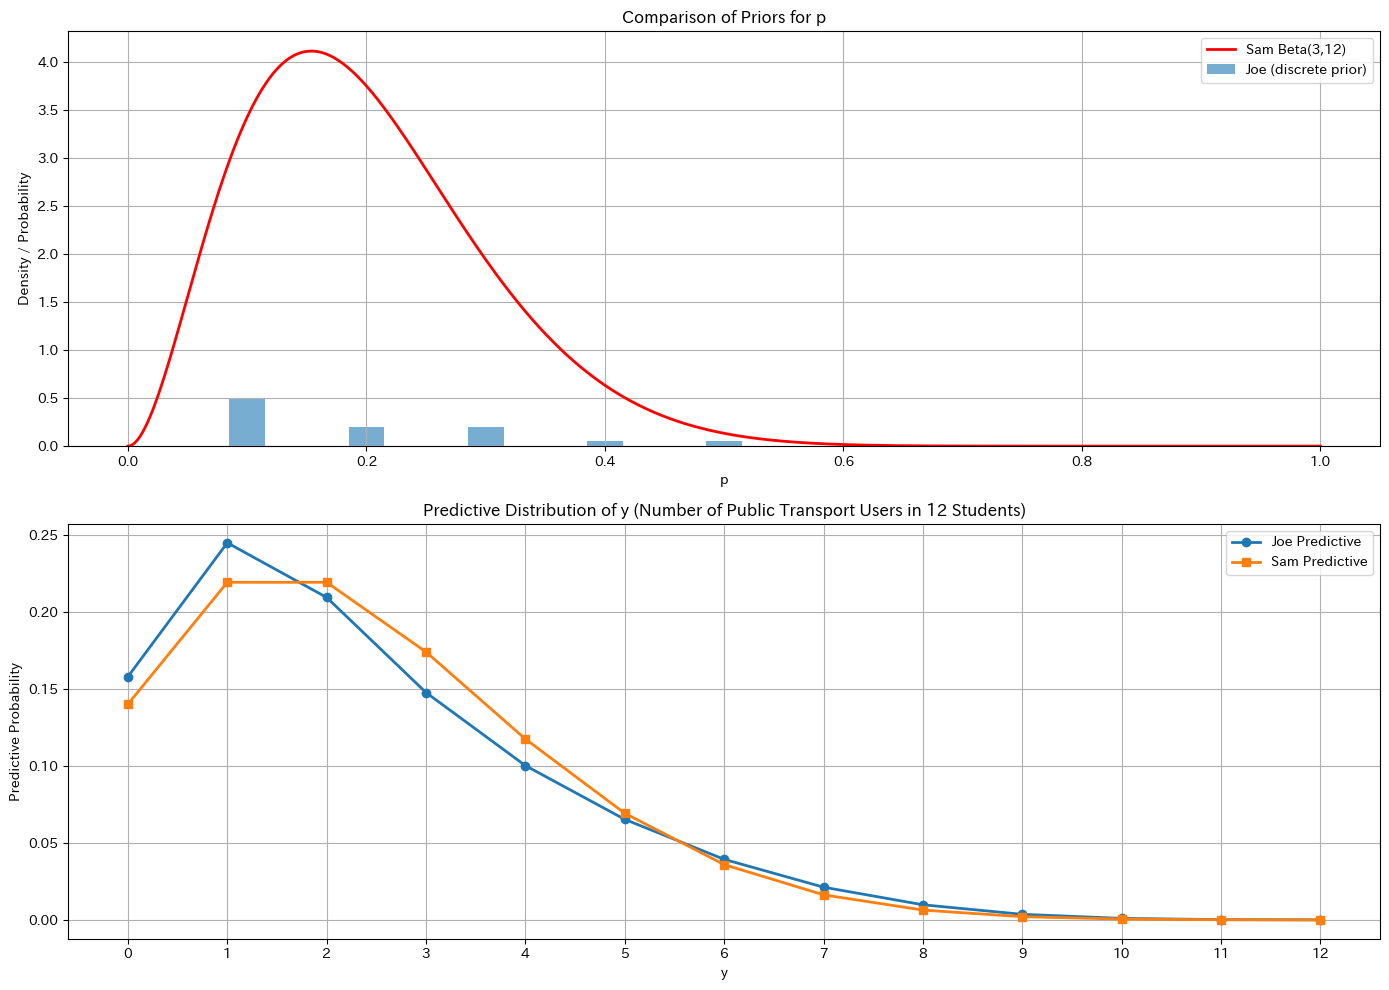

In [ ]:
# -----------------------------
# 1. 事前分布の準備
# -----------------------------

# --- ジョー（離散事前） ---
p_vals = np.array([0.1, 0.2, 0.3, 0.4, 0.5])
g = np.array([0.5, 0.2, 0.2, 0.05, 0.05])   # weight

# --- サム（Beta(3,12)） ---
a, b = 3, 12
p_grid = np.linspace(0, 1, 500)

# -----------------------------
# 2. 予測分布（y=0〜12）
# -----------------------------

N = 12
y_vals = np.arange(0, N+1)

# --- ジョーの予測分布 ---
joe_predictive = np.zeros_like(y_vals, dtype=float)
for p, w in zip(p_vals, g):
    joe_predictive += w * binom.pmf(y_vals, N, p)

# --- サムの予測分布（ベータ二項） ---
sam_predictive = betabinom(N, a, b).pmf(y_vals)

# -----------------------------
# 3. グラフ描画
# -----------------------------

plt.figure(figsize=(14, 10))

# (1) 事前分布の比較 --------------------------------
plt.subplot(2, 1, 1)
# ジョー（棒グラフ）
plt.bar(p_vals, g, width=0.03, alpha=0.6, label="Joe (discrete prior)")
# サム（Beta密度）
plt.plot(p_grid, beta.pdf(p_grid, a, b), 'r-', label="Sam Beta(3,12)", linewidth=2)

plt.title("Comparison of Priors for p")
plt.xlabel("p")
plt.ylabel("Density / Probability")
plt.legend()
plt.grid(True)

# (2) 予測分布の比較（y ~ Binomial(12,p)） ----------------
plt.subplot(2, 1, 2)
plt.plot(y_vals, joe_predictive, 'o-', label="Joe Predictive", linewidth=2)
plt.plot(y_vals, sam_predictive, 's-', label="Sam Predictive", linewidth=2)

plt.title("Predictive Distribution of y (Number of Public Transport Users in 12 Students)")
plt.xlabel("y")
plt.ylabel("Predictive Probability")
plt.xticks(y_vals)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


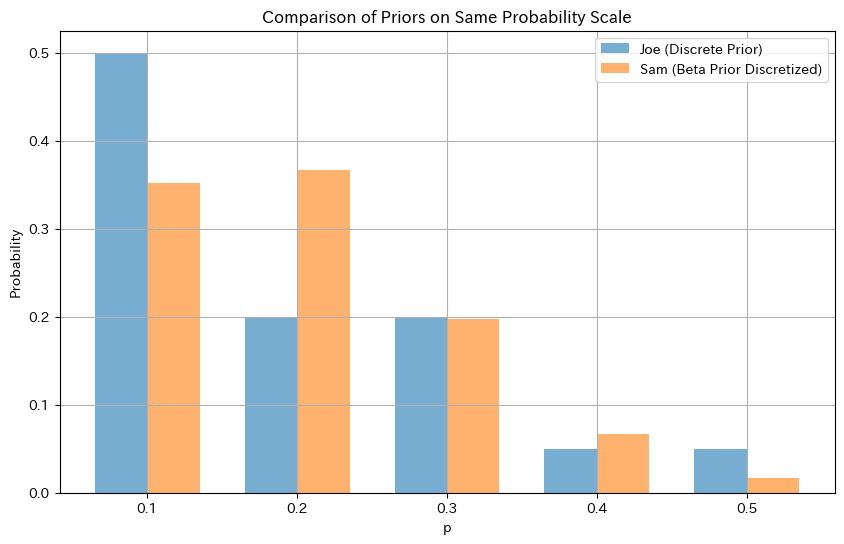

In [ ]:
# -----------------------------
# 1. 事前分布の準備
# -----------------------------
p_vals = np.array([0.1, 0.2, 0.3, 0.4, 0.5])
g = np.array([0.5, 0.2, 0.2, 0.05, 0.05])

# サムの Beta(3,12)
a, b = 3, 12

# -----------------------------
# 2. サムのベータ分布を "ジョーと同じ区間" で離散化
# -----------------------------
# p=0.1 の場合 → 区間 [0.05,0.15] とみなす
# 端は [0,0.15], [...,1] に補正
edges = np.zeros(len(p_vals) + 1)
edges[1:-1] = (p_vals[:-1] + p_vals[1:]) / 2
edges[0] = 0
edges[-1] = 1

sam_discrete = np.array([
    beta.cdf(edges[i+1], a, b) - beta.cdf(edges[i], a, b)
    for i in range(len(p_vals))
])

# 規格化（誤差への保険）
sam_discrete /= sam_discrete.sum()

# -----------------------------
# 3. グラフ描画（両方とも棒グラフ）
# -----------------------------
plt.figure(figsize=(10, 6))

width = 0.035

plt.bar(p_vals - width/2, g, width=width, alpha=0.6, label="Joe (Discrete Prior)")
plt.bar(p_vals + width/2, sam_discrete, width=width, alpha=0.6, label="Sam (Beta Prior Discretized)")

plt.title("Comparison of Priors on Same Probability Scale")
plt.xlabel("p")
plt.ylabel("Probability")
plt.grid(True)
plt.legend()

plt.show()


### 2.9.5 練習問題

離散事前分布を使った正規分布の平均確定。

ある大都市での年間総積雪量平均 $ \mu $ を推定したいとする。年ごとの積雪量の合計 $ y_1, .. y_n $ が、平均 $ \mu $ で既知の標準偏差 $ \sigma = 10 $ の正規分布からの標本だとする。

1. データを収集する前に、積雪量の平均 $ \mu $ は、20, 30, 40, 50, 60 70のいずれかの値で、ありそれぞれ次の確率が対応すると考えている。 $ g(\mu) : 0.1, 0.15, 0.25, 0.25, 0.15, 0.1 $

2. さて、年間総降雪量として、38.6, 42.4, 57.5, 40.5, 51.7, 67.1, 33.4, 60.9, 64.1, 40.1, 40.7, 6.4 というデータが与えられたとする。

3. この事例の $ \mu $ の事後確率を計算せよ。また、８０％の確率区間を求めよ。

In [ ]:
# --- 1. 事前分布（離散） ---
mu_values = np.array([20, 30, 40, 50, 60, 70])  # 候補値
prior = np.array([0.1, 0.15, 0.25, 0.25, 0.15, 0.1])  # 事前確率

# --- 2. 観測データ ---
y = np.array([38.6, 42.4, 57.5, 40.5, 51.7, 67.1, 33.4, 60.9, 64.1, 40.1, 40.7, 6.4])
sigma = 10
n = len(y)

# --- 3. 事後確率の計算 ---
# 尤度： p(y | mu) = Π Normal(y_i | mu, sigma)
likelihood = np.array([
    np.prod(norm.pdf(y, loc=mu, scale=sigma))
    for mu in mu_values
])

# 未規格化事後分布
posterior_unnorm = likelihood * prior

# 正規化
posterior = posterior_unnorm / posterior_unnorm.sum()

# 表示用データフレーム
df = pd.DataFrame({
    "mu": mu_values,
    "prior": prior,
    "likelihood": likelihood,
    "posterior": posterior
})

print("=== 事後確率 ===")
print(df[["mu", "posterior"]])

# --- 4. 80% HPD 区間の計算（離散分布なので最も確率の高い順に積算） ---
sorted_idx = np.argsort(posterior)[::-1]
sorted_mu = mu_values[sorted_idx]
sorted_post = posterior[sorted_idx]

cum_prob = np.cumsum(sorted_post)

# 80%までの mu を抽出
hpd_mu = sorted_mu[cum_prob <= 0.80]
# 境界の1点を追加（80%を超える最初の値）
if cum_prob[0] > 0.80:
    hpd_mu = sorted_mu[:1]
else:
    idx_edge = np.where(cum_prob > 0.80)[0][0]
    hpd_mu = np.append(hpd_mu, sorted_mu[idx_edge])

print("\n=== 80% HPD 区間 ===")
print(sorted(hpd_mu))


=== 事後確率 ===
   mu     posterior
0  20  1.954479e-17
1  30  1.091063e-06
2  40  4.158078e-01
3  50  5.841881e-01
4  60  3.025731e-06
5  70  1.069871e-16

=== 80% HPD 区間 ===
[np.int64(40), np.int64(50)]


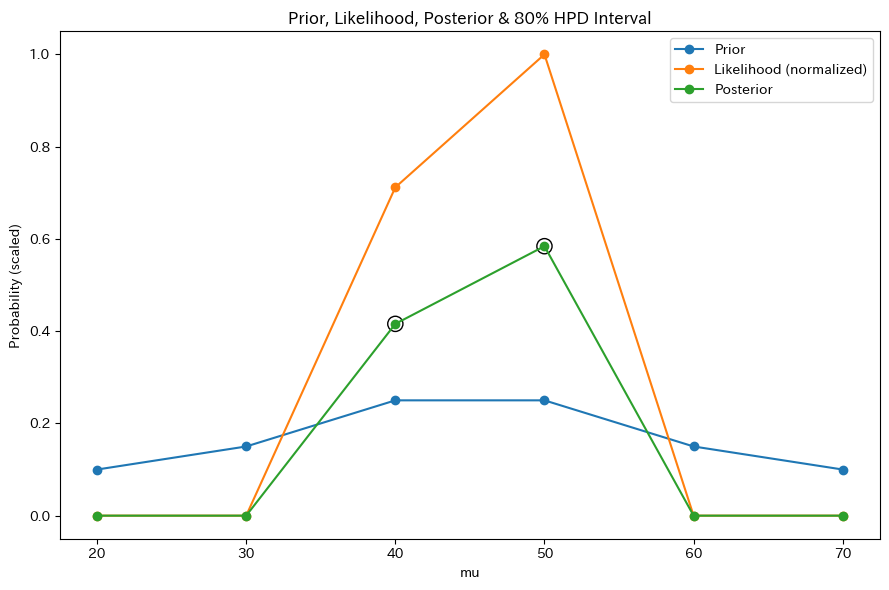

In [ ]:
# --- Data ---
mu_values = np.array([20, 30, 40, 50, 60, 70])
prior = np.array([0.1, 0.15, 0.25, 0.25, 0.15, 0.1])
y = np.array([38.6, 42.4, 57.5, 40.5, 51.7, 67.1, 33.4, 60.9, 64.1, 40.1, 40.7, 6.4])
sigma = 10

# Likelihood
likelihood = np.array([
    np.prod(norm.pdf(y, loc=mu, scale=sigma))
    for mu in mu_values
])
likelihood_norm = likelihood / likelihood.max()

# Posterior
posterior_unnorm = likelihood * prior
posterior = posterior_unnorm / posterior_unnorm.sum()

# HPD 80%
sorted_idx = np.argsort(posterior)[::-1]
sorted_mu = mu_values[sorted_idx]
sorted_post = posterior[sorted_idx]
cum_prob = np.cumsum(sorted_post)

hpd_mu = sorted_mu[cum_prob <= 0.80]
if cum_prob[0] > 0.80:
    hpd_mu = sorted_mu[:1]
else:
    idx_edge = np.where(cum_prob > 0.80)[0][0]
    hpd_mu = np.append(hpd_mu, sorted_mu[idx_edge])

# --- Combined Plot ---
plt.figure(figsize=(9,6))

plt.plot(mu_values, prior, marker="o", label="Prior")
plt.plot(mu_values, likelihood_norm, marker="o", label="Likelihood (normalized)")
plt.plot(mu_values, posterior, marker="o", label="Posterior")

# Mark HPD region points
for m in hpd_mu:
    plt.scatter(m, posterior[mu_values==m], s=120, edgecolor="black", facecolor="none")

plt.xlabel("mu")
plt.ylabel("Probability (scaled)")
plt.title("Prior, Likelihood, Posterior & 80% HPD Interval")
plt.legend()
plt.tight_layout()
plt.show()


### 2.9.6 練習問題

離散事前密度を利用したポワソン平均の推定

トラック運送会社を所収しており、多くのトラックを抱えている。時折ランダムにトラックに故障が生じる。t日の区間に故障するトラック数は平均 $ t\lambda $ のポワソン分布に従う。パラメータ $ \lambda $ は一日当たりに故障する故障率である。$ \lambda $ の値として可能なのは、0.5, 1, 1.5, 2, 2.5, 3 で、それぞれの確率は、0.1,0.2,0.3,0.2,0.15,0.05 と想定される。

1. 仮に6日に１２台のトラックが壊れるとすると、1日あたりの各故障率に見込まれる事後確率を求めよ。

2. 次の週に故障が全く起きない確率を求めよ。

In [ ]:
from scipy.stats import poisson

# --- 1. 離散事前分布 ---
lambda_values = np.array([0.5, 1, 1.5, 2, 2.5, 3])
prior = np.array([0.1, 0.2, 0.3, 0.2, 0.15, 0.05])

# --- 2. 観測データ ---
t = 6          # 日数
y = 12         # 故障台数

# --- 3. 尤度： p(y | λ) = Poisson(y | t * λ) ---
likelihood = poisson.pmf(y, t * lambda_values)

# --- 4. 事後確率 ---
posterior_unnorm = likelihood * prior
posterior = posterior_unnorm / posterior_unnorm.sum()

# 表示用データフレーム
df = pd.DataFrame({
    "lambda": lambda_values,
    "prior": prior,
    "likelihood": likelihood,
    "posterior": posterior
})

print("=== 1. λ の事後確率 ===")
print(df[["lambda", "posterior"]])

# --- 5. 次の週（7日間）に故障ゼロの確率 ---
# p(Y=0 | λ) = Poisson(0 | 7λ) = exp(-7λ)
p_zero_given_lambda = np.exp(-7 * lambda_values)

# 事後予測分布（混合ポワソン）
p_zero_next_week = np.sum(p_zero_given_lambda * posterior)

print("\n=== 2. 次の週に故障ゼロの確率 ===")
print(f"{p_zero_next_week:.6f}")


=== 1. λ の事後確率 ===
   lambda  posterior
0     0.5   0.000090
1     1.0   0.036794
2     1.5   0.356520
3     2.0   0.373571
4     2.5   0.202989
5     3.0   0.030036

=== 2. 次の週に故障ゼロの確率 ===
0.000046


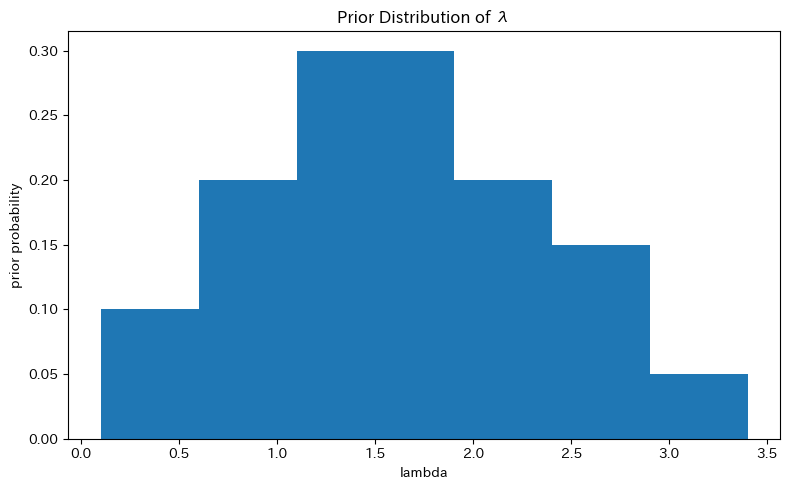

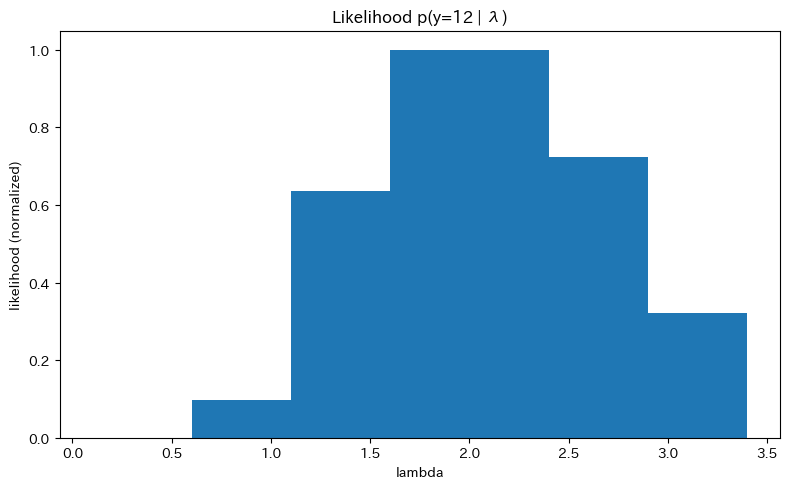

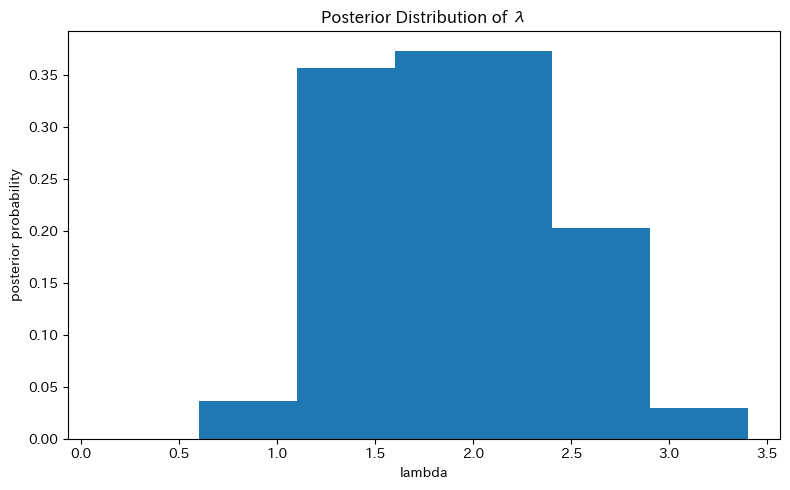

In [ ]:
# --- Data ---
lambda_values = np.array([0.5, 1, 1.5, 2, 2.5, 3])
prior = np.array([0.1, 0.2, 0.3, 0.2, 0.15, 0.05])

t = 6
y = 12

likelihood = poisson.pmf(y, t * lambda_values)
likelihood_norm = likelihood / likelihood.max()

posterior_unnorm = likelihood * prior
posterior = posterior_unnorm / posterior_unnorm.sum()

# --- Plot 1: Prior ---
plt.figure(figsize=(8,5))
plt.bar(lambda_values, prior)
plt.xlabel("lambda")
plt.ylabel("prior probability")
plt.title("Prior Distribution of λ")
plt.tight_layout()
plt.show()

# --- Plot 2: Likelihood (normalized) ---
plt.figure(figsize=(8,5))
plt.bar(lambda_values, likelihood_norm)
plt.xlabel("lambda")
plt.ylabel("likelihood (normalized)")
plt.title("Likelihood p(y=12 | λ)")
plt.tight_layout()
plt.show()

# --- Plot 3: Posterior ---
plt.figure(figsize=(8,5))
plt.bar(lambda_values, posterior)
plt.xlabel("lambda")
plt.ylabel("posterior probability")
plt.title("Posterior Distribution of λ")
plt.tight_layout()
plt.show()
